# Introduction
This script is about the computer vision analysis done through our camera.

Objectives:
- Camera calibration
- Definition of the actual position of the Thymio
- Definition of the final position
- Definition of the obstacles positions

In [1]:
!pip install opencv-python
!pip install numpy

## Camera calibration

In [2]:

import cv2
import numpy as np

# Read image
image = cv2.imread("ThymioSetup.jfif")

if image is None:
    raise ValueError("Image not found")

# Detect QR codes
detector = cv2.QRCodeDetector()
retval, points = detector.detectMulti(image)

if not retval or points is None or len(points) != 4:
    raise ValueError("Exactly 4 QR codes are required")

markers = points.reshape(4, 4, 2)

# Order each QR code's corners geometrically
def order_corners(p):
    s = p.sum(axis=1)
    d = np.diff(p, axis=1).flatten()

    return np.array([
        p[np.argmin(s)],  # top left
        p[np.argmin(d)],  # top right
        p[np.argmax(s)],  # bottom right
        p[np.argmax(d)]   # bottom left
    ], dtype=np.float32)

markers = np.array([
    order_corners(m) for m in markers
])

# Find QR code centers
centers = markers.mean(axis=1)

# Sort QR codes by vertical position
idx = np.argsort(centers[:, 1])

top = markers[idx[:2]]
bottom = markers[idx[2:]]

# Sort left to right
top = sorted(top, key=lambda p: p[:, 0].mean())
bottom = sorted(bottom, key=lambda p: p[:, 0].mean())

# Take ONLY the 4 external corners
src = np.array([
    top[0][0],       # top left QR: top left corner
    top[1][1],       # top right QR: top right corner
    bottom[1][2],    # bottom right QR: bottom right corner
    bottom[0][3]     # bottom left QR: bottom left corner
], dtype=np.float32)

# Desired rectangular output
width = 205
height = 155

dst = np.array([
    [0, 0],
    [width - 1, 0],
    [width - 1, height - 1],
    [0, height - 1]
], dtype=np.float32)

# Calculate homography
H = cv2.getPerspectiveTransform(src, dst)

# Rectify the entire image
rectified_image = cv2.warpPerspective(
    image,
    H,
    (width, height)
)

# Display
cv2.imshow("Original", image)
cv2.imshow("Rectified image", rectified_image)

cv2.waitKey(0)
cv2.destroyAllWindows()

cv2.imwrite("Rectified_Thymio.png", rectified_image)


True

## Actual position definition

In [3]:

# ==========================================
# 1. CONVERT RECTIFIED IMAGE TO HSV
# ==========================================

hsv = cv2.cvtColor(rectified_image, cv2.COLOR_BGR2HSV)

# ==========================================
# 2. DEFINE COLOR RANGES
# ==========================================

# RED
lower_red1 = np.array([0, 100, 100])
upper_red1 = np.array([10, 255, 255])

lower_red2 = np.array([160, 100, 100])
upper_red2 = np.array([180, 255, 255])

# GREEN
lower_green = np.array([35, 80, 80])
upper_green = np.array([90, 255, 255])

# ==========================================
# 3. CREATE MASKS
# ==========================================

mask_red1 = cv2.inRange(hsv, lower_red1, upper_red1)
mask_red2 = cv2.inRange(hsv, lower_red2, upper_red2)

mask_red = cv2.bitwise_or(mask_red1, mask_red2)

mask_green = cv2.inRange(
    hsv,
    lower_green,
    upper_green
)

# ==========================================
# 4. FIND CONTOURS
# ==========================================

contours_red, _ = cv2.findContours(
    mask_red,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

contours_green, _ = cv2.findContours(
    mask_green,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

# ==========================================
# 5. FETCH POSITIONS
# ==========================================

def find_position(contours):

    valid_contours = [
        c for c in contours
        if cv2.contourArea(c) > 5
    ]

    if not valid_contours:
        return None

    # Select largest detected object
    contour = max(valid_contours, key=cv2.contourArea)

    M = cv2.moments(contour)

    if M["m00"] == 0:
        return None

    x = int(M["m10"] / M["m00"])
    y = int(M["m01"] / M["m00"])

    return (x, y)


red_position = find_position(contours_red)
green_position = find_position(contours_green)

# ==========================================
# 6. DISPLAY POSITIONS
# ==========================================

result = rectified_image.copy()

if red_position is not None:

    x_red, y_red = red_position

    cv2.circle(
        result,
        red_position,
        5,
        (0, 0, 255),
        -1
    )

    print("Red point:", x_red, y_red)

else:
    print("Red point not detected")


if green_position is not None:

    x_green, y_green = green_position

    cv2.circle(
        result,
        green_position,
        5,
        (0, 255, 0),
        -1
    )

    print("Green point:", x_green, y_green)

else:
    print("Green point not detected")


# ==========================================
# 7. DISPLAY RESULT
# ==========================================

cv2.imshow("Plan 2D - Red and Green Points", result)

cv2.waitKey(0)
cv2.destroyAllWindows()


Red point: 145 108
Green point: 149 121


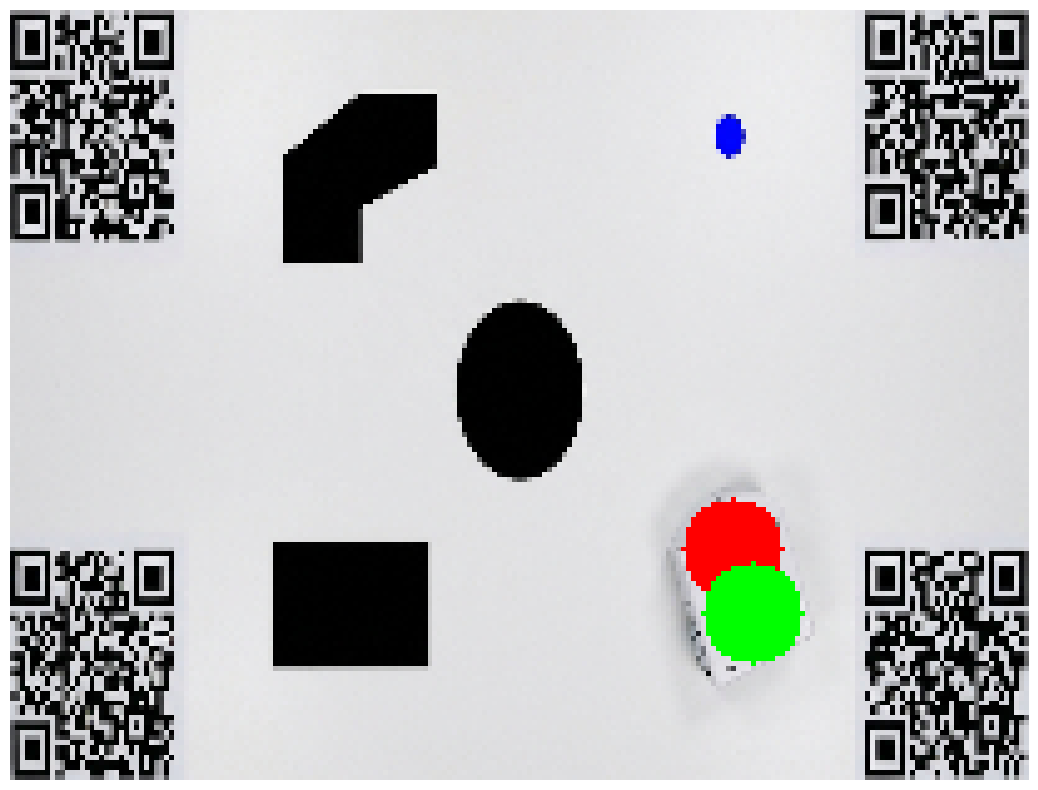

In [4]:
import matplotlib.pyplot as plt

# Copie de l'image rectifiée
image_display = rectified_image.copy()

# Dessiner les points détectés
if red_position is not None:
    cv2.circle(image_display, red_position, 10, (0, 0, 255), -1)

if green_position is not None:
    cv2.circle(image_display, green_position, 10, (0, 255, 0), -1)

# Afficher l'image en grand dans Jupyter
plt.figure(figsize=(12, 8))
plt.imshow(cv2.cvtColor(image_display, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.tight_layout()
plt.show()

## Final position definition

Blue point: 144 24


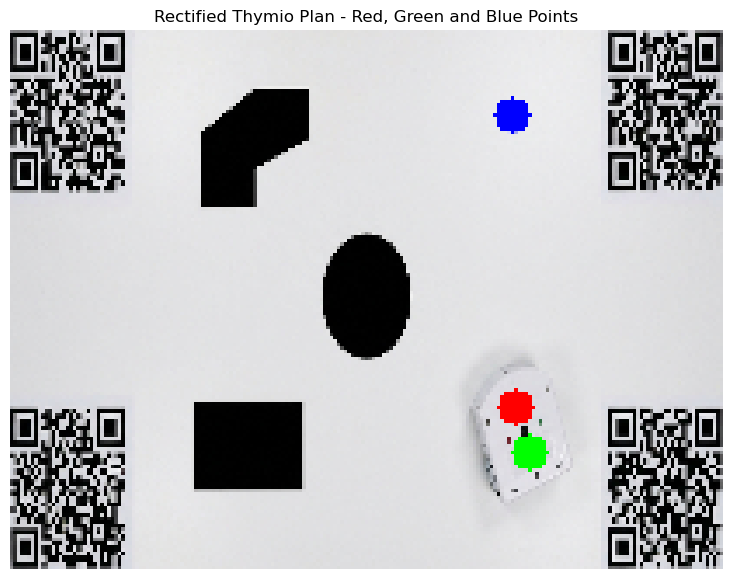

True

In [5]:

# ==========================================
# 8. FIND THE BLUE POINT
# ==========================================

# Define BLUE HSV range
lower_blue = np.array([100, 100, 100])
upper_blue = np.array([130, 255, 255])

# Create blue mask
mask_blue = cv2.inRange(
    hsv,
    lower_blue,
    upper_blue
)

# Find blue contours
contours_blue, _ = cv2.findContours(
    mask_blue,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

# ==========================================
# 9. FETCH BLUE POSITION
# ==========================================

blue_position = find_position(contours_blue)

# ==========================================
# 10. DISPLAY BLUE POSITION
# ==========================================

if blue_position is not None:

    x_blue, y_blue = blue_position

    cv2.circle(
        result,
        blue_position,
        5,
        (255, 0, 0),  # Blue in BGR
        -1
    )

    print("Blue point:", x_blue, y_blue)

else:
    print("Blue point not detected")

# ==========================================
# 11. DISPLAY FINAL RESULT
# ==========================================

cv2.imshow("Plan 2D - Red, Green and Blue Points", result)

cv2.waitKey(0)
cv2.destroyAllWindows()


# ==========================================
# DISPLAY FINAL IMAGE IN JUPYTER
# ==========================================

# Convert BGR to RGB for matplotlib
result_rgb = cv2.cvtColor(result, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 7))
plt.imshow(result_rgb)
plt.title("Rectified Thymio Plan - Red, Green and Blue Points")
plt.axis("off")
plt.show()

# Save final image
cv2.imwrite("Final_Thymio_Points.png", result)


## Obstacle position definition

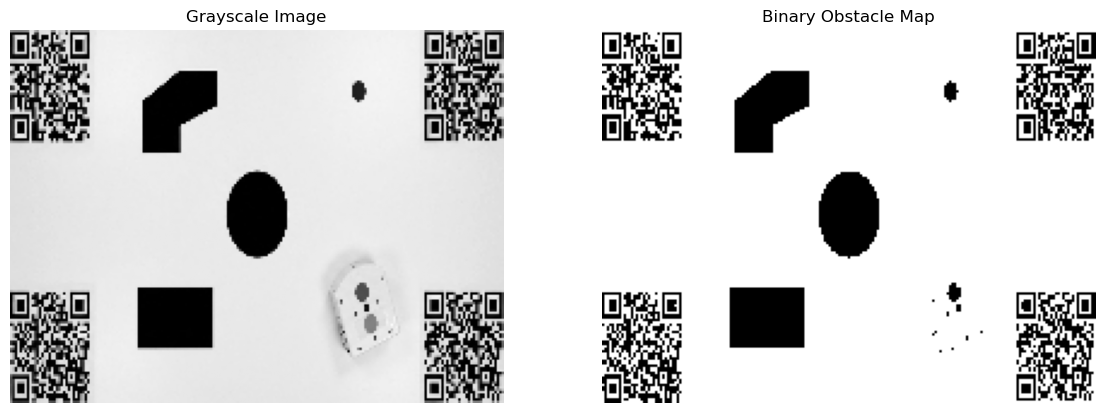

In [6]:

# ==========================================
# 1. DEFINE GREY THRESHOLD
# ==========================================

grey_threshold = 80

# ==========================================
# 2. CONVERT IMAGE TO GRAYSCALE
# ==========================================

grey_image = cv2.cvtColor(
    rectified_image,
    cv2.COLOR_BGR2GRAY
)

# ==========================================
# 3. CREATE BINARY OBSTACLE MATRIX
# ==========================================

# 0 = Obstacle (black)
# 1 = Free space (white)

obstacle_image = np.zeros(grey_image.shape, dtype=np.uint8)

for y in range(grey_image.shape[0]):
    for x in range(grey_image.shape[1]):

        if grey_image[y, x] <= grey_threshold:
            obstacle_image[y, x] = 0
        else:
            obstacle_image[y, x] = 255

# ==========================================
# 4. DISPLAY RESULTS IN JUPYTER
# ==========================================

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.imshow(grey_image, cmap='gray')
plt.title("Grayscale Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(obstacle_image, cmap='gray', vmin=0, vmax=255)
plt.title("Binary Obstacle Map")
plt.axis("off")

plt.show()


## Final map: obstacles and points

Red point: x = 145, y = 108
Green point: x = 149, y = 121
Blue point: x = 144, y = 24
Thymio average position (red + green): x = 147.0, y = 114.5


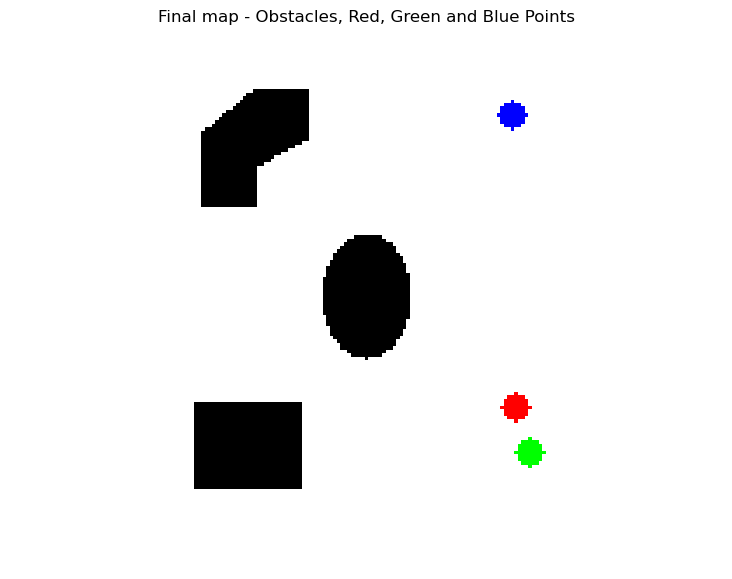

In [7]:

# ==========================================
# 1. WHITE BACKGROUND
# ==========================================

final_map = np.full((height, width, 3), 255, dtype=np.uint8)

# ==========================================
# 2. OBSTACLES IN BLACK
# ==========================================

# Reuse the binary obstacle map (0 = obstacle)
# The colored points are removed from the obstacles so they are not drawn in black
color_mask = cv2.bitwise_or(cv2.bitwise_or(mask_red, mask_green), mask_blue)
color_mask = cv2.dilate(color_mask, np.ones((3, 3), np.uint8), iterations=1)

obstacle_mask = (obstacle_image == 0) & (color_mask == 0)

# Remove the 4 QR codes: project their corners into the rectified image with H
qr_mask = np.zeros((height, width), dtype=np.uint8)
qr_corners_rectified = cv2.perspectiveTransform(markers.reshape(-1, 1, 2), H).reshape(4, 4, 2)

for qr in qr_corners_rectified:
    cv2.fillConvexPoly(qr_mask, np.round(qr).astype(np.int32), 255)

qr_mask = cv2.dilate(qr_mask, np.ones((5, 5), np.uint8), iterations=1)
obstacle_mask &= (qr_mask == 0)

# Remove the small noise blobs (keep only obstacles bigger than min_obstacle_area pixels)
min_obstacle_area = 20

n_labels, labels, stats, _ = cv2.connectedComponentsWithStats(
    obstacle_mask.astype(np.uint8),
    connectivity=8
)

for label in range(1, n_labels):  # label 0 = background
    if stats[label, cv2.CC_STAT_AREA] < min_obstacle_area:
        obstacle_mask[labels == label] = False

final_map[obstacle_mask] = (0, 0, 0)

# ==========================================
# 3. RED, GREEN AND BLUE POINTS
# ==========================================

detected_points = {
    "Red":   (red_position,   (0, 0, 255)),   # BGR
    "Green": (green_position, (0, 255, 0)),
    "Blue":  (blue_position,  (255, 0, 0)),
}

for name, (position, color) in detected_points.items():
    if position is not None:
        cv2.circle(final_map, position, 4, color, -1)

# ==========================================
# 4. THYMIO AVERAGE POSITION (RED + GREEN)
# ==========================================

if red_position is not None and green_position is not None:
    thymio_position = (
        (red_position[0] + green_position[0]) / 2,
        (red_position[1] + green_position[1]) / 2
    )
else:
    thymio_position = None

# ==========================================
# 5. PRINT POSITIONS
# ==========================================

for name, (position, _) in detected_points.items():
    if position is not None:
        print(f"{name} point: x = {position[0]}, y = {position[1]}")
    else:
        print(f"{name} point not detected")

if thymio_position is not None:
    print(f"Thymio average position (red + green): x = {thymio_position[0]:.1f}, y = {thymio_position[1]:.1f}")
else:
    print("Thymio average position cannot be computed (red or green point missing)")

# ==========================================
# 6. DISPLAY FINAL MAP
# ==========================================

plt.figure(figsize=(10, 7))
plt.imshow(cv2.cvtColor(final_map, cv2.COLOR_BGR2RGB))
plt.title("Final map - Obstacles, Red, Green and Blue Points")
plt.axis("off")
plt.show()
